# Part A: Customer Segmentation (Unsupervised Learning)

## Project Overview

The aim of this project is to group a shopping mall's customers into **segments with similar characteristics**, so that marketing can be targeted at each group instead of treating every customer the same way. Because there are no labels telling us which group a customer belongs to, this is an **unsupervised learning (clustering)** problem.

**Dataset:** `CA2-Customer-Data.csv`: 200 customers, 5 columns

| Column | Description | Used for clustering? |
|---|---|---|
| `CustomerID` | Unique identifier | No (identifier only) |
| `Gender` | Male / Female | No (used afterwards to profile the clusters) |
| `Age` | Age in years | **Yes** |
| `Income (k$)` | Annual income in thousands of dollars | **Yes** |
| `How Much They Spend` | Spending score (1–100) | **Yes** |

**Workflow**

1. **Setup & Data Loading:** importing libraries and inspecting the dataset.
2. **Exploratory Data Analysis (EDA):** distributions, gender balance, pairwise relationships and outliers.
3. **Preprocessing:** capping income outliers, dropping the ID and scaling the features.
4. **Choosing the Number of Clusters (k):** elbow method, silhouette scores and the dendrogram.
5. **Model Building & Evaluation:** K-Means vs Agglomerative (Hierarchical) Clustering, compared with three internal metrics.
6. **Cluster Interpretation:** profiling each segment by age, income, spending and gender.
7. **Business Recommendations & Conclusion.**

## Step 1: Setup & Load Data
### 1.1 Importing Libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram

# Preprocessing, models & metrics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

import os, warnings
os.environ["OMP_NUM_THREADS"] = "1"      # avoids the K-Means memory-leak warning on Windows
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

### 1.2 Loading the Dataset

In [2]:
df_raw = pd.read_csv("C:/Users/yyuel/Downloads/CA2-Customer-Data.csv")
df = df_raw.copy()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Income (k$),How Much They Spend
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1.3 Data Types, Summary Statistics & Missing Values

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CustomerID           200 non-null    int64 
 1   Gender               200 non-null    object
 2   Age                  200 non-null    int64 
 3   Income (k$)          200 non-null    int64 
 4   How Much They Spend  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.describe().round(2)

,CustomerID,Age,Income (k$),How Much They Spend
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
CustomerID             0
Gender                 0
Age                    0
Income (k$)            0
How Much They Spend    0
dtype: int64

Duplicate rows: 0


**Observations**

- The dataset has **200 customers**, with **no missing values** and **no duplicate rows**.
- **Age** ranges from **18 to 70** (median 36).
- **Income** ranges from **\$15k to \$137k** (median \$61.5k). The maximum is far above the 75th percentile (\$78k), which suggests a few high-income outliers.
- **Spending score** covers almost the full **1–99** range, with a median of 50.
- `Gender` is the only text column. `CustomerID` is an identifier and has no meaning for clustering.

## Step 2: Exploratory Data Analysis (EDA)
### 2.1 Distribution of Numerical Features

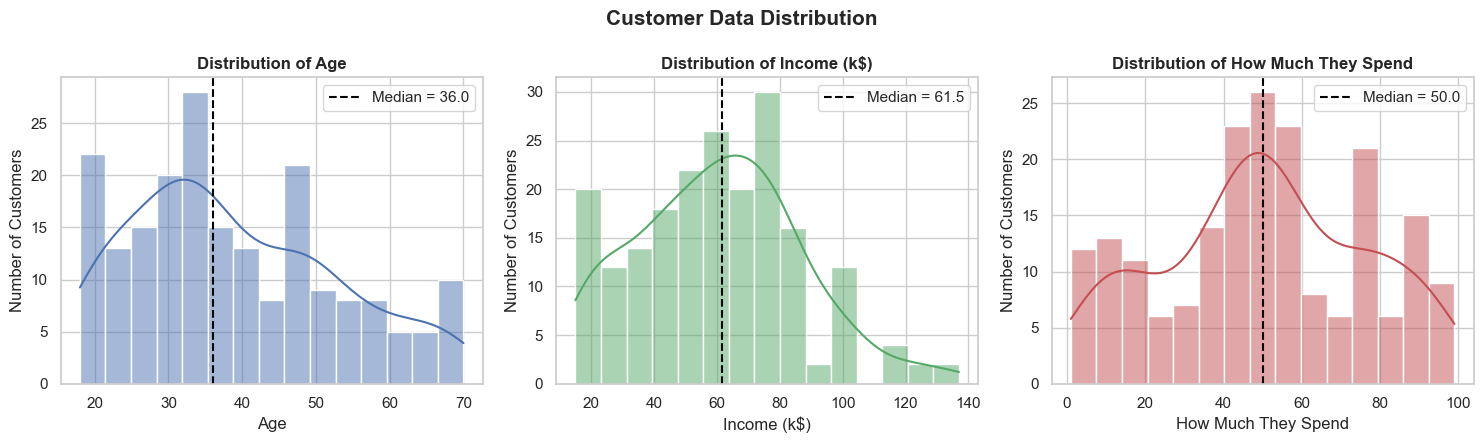

In [6]:
numeric_cols = ["Age", "Income (k$)", "How Much They Spend"]
colors = ["#4C72B0", "#55A868", "#C44E52"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, c in zip(axes, numeric_cols, colors):
    sns.histplot(df[col], bins=15, kde=True, color=c, ax=ax)
    ax.axvline(df[col].median(), color="black", linestyle="--", label=f"Median = {df[col].median():.1f}")
    ax.set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Number of Customers")
    ax.legend()
plt.suptitle("Customer Data Distribution", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

- **Age:** most customers are between **20 and 50**, with the largest group in their **early 30s**. Fewer customers are over 55.
- **Income:** most customers earn between **\$40k and \$80k**. The distribution has a **right tail**, with a small number of customers earning above \$110k.
- **Spending score:** the largest group sits in the **middle (40–60)**, with smaller groups at the low end (below 20) and the high end (75+). These separate low-, mid- and high-spender groups already hint at natural segments.

### 2.2 Gender Balance

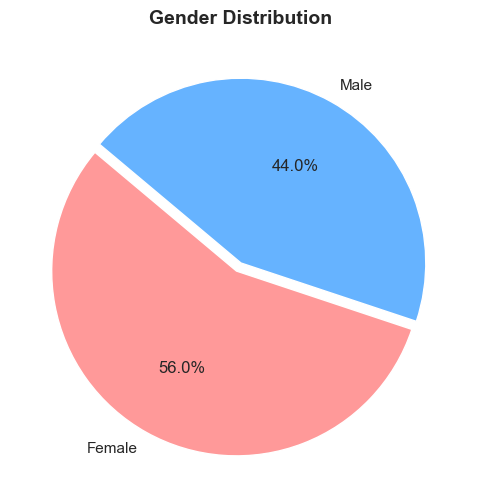

Gender
Female    112
Male       88
Name: count, dtype: int64


In [7]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%", startangle=140,
        colors=["#ff9999", "#66b3ff"], explode=(0.05, 0), wedgeprops={"edgecolor": "white"})
plt.title("Gender Distribution", fontsize=14, fontweight="bold")
plt.show()

print(gender_counts)

**Female customers make up 56%** of the dataset (112) and **male customers 44%** (88). The two groups are reasonably balanced, so neither gender dominates the data.

### 2.3 Pairwise Relationships

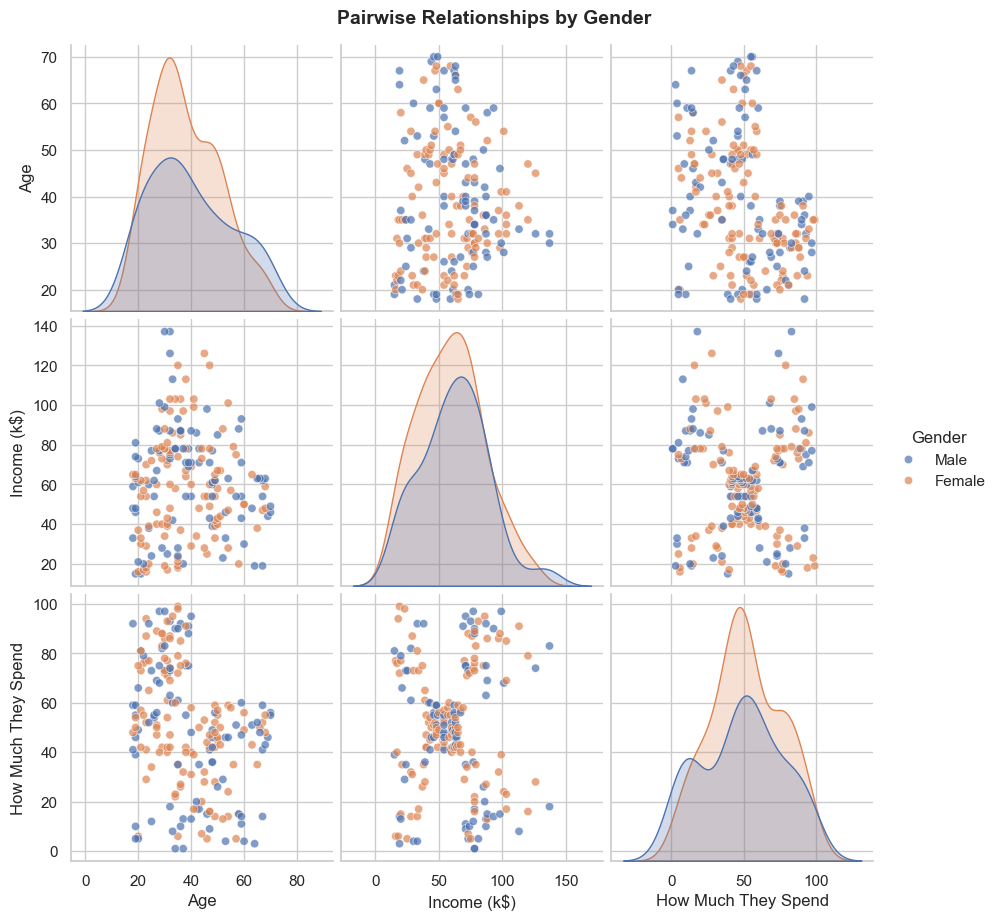

In [8]:
g = sns.pairplot(df, hue="Gender", vars=numeric_cols, plot_kws={"alpha": 0.7}, height=3)
g.fig.suptitle("Pairwise Relationships by Gender", y=1.02, fontsize=14, fontweight="bold")
plt.show()

- **Income vs Spending** shows the clearest structure: customers form roughly **five visible groups**. These are low income with low or high spending, middle income with middle spending, and high income with low or high spending. Income alone therefore does **not** determine how much someone spends.
- **Age vs Spending:** the **highest spending scores (above 60) come almost entirely from customers under about 40**. Older customers mostly have low-to-mid spending.
- **Male and female customers overlap in every plot**, which suggests gender does not drive these patterns.

### 2.4 Outlier Detection

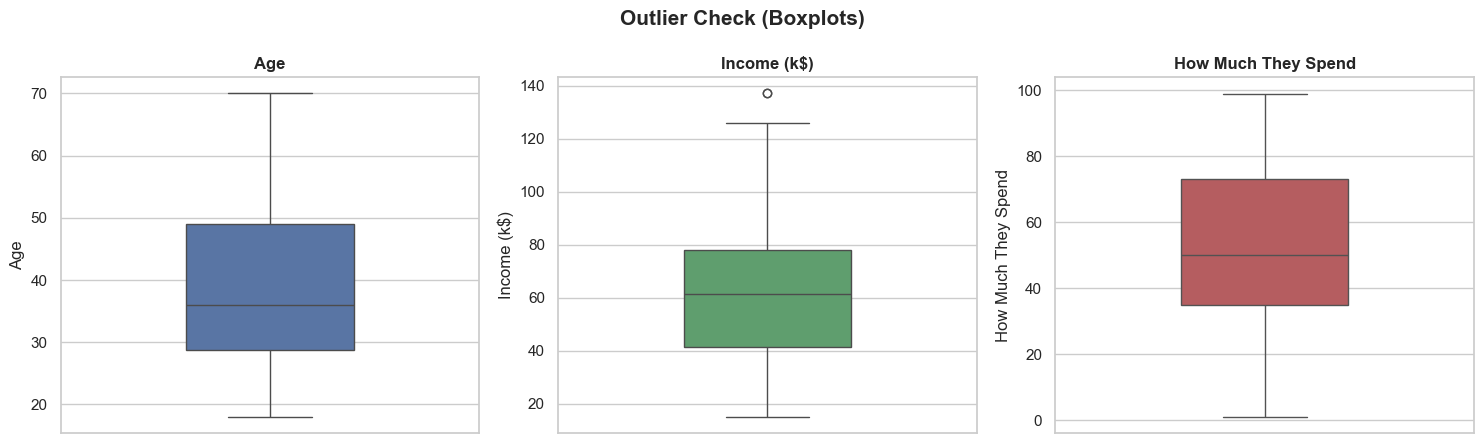

Income upper fence (Q3 + 1.5×IQR): 132.8k


,CustomerID,Gender,Age,Income (k$),How Much They Spend
198,199,Male,32,137,18
199,200,Male,30,137,83


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, c in zip(axes, numeric_cols, colors):
    sns.boxplot(y=df[col], ax=ax, color=c, width=0.4)
    ax.set_title(f"{col}", fontsize=12, fontweight="bold")
plt.suptitle("Outlier Check (Boxplots)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# IQR rule for income
Q1, Q3 = df["Income (k$)"].quantile([0.25, 0.75])
upper_fence = Q3 + 1.5 * (Q3 - Q1)
print(f"Income upper fence (Q3 + 1.5×IQR): {upper_fence:.1f}k")
df[df["Income (k$)"] > upper_fence]

- **Age** and **Spending** have **no outliers**.
- **Income** has **2 outliers**: two customers earning **\$137k**, above the IQR upper fence.

These are likely genuine high earners rather than data errors, so they are **kept but capped** in Step 3. Removing them would lose real customers. Leaving them uncapped would stretch the income scale and squeeze everyone else into a narrow range after Min-Max scaling.

### EDA Summary
- The data is clean: no missing values and no duplicates.
- **Income vs Spending** shows clear visual groups, so clustering is likely to find meaningful segments.
- **Younger customers spend more**, and income alone does not determine spending.
- Gender appears to have little effect, so it is left out of the clustering and used only to describe the clusters afterwards.
- Two high-income outliers need to be capped before scaling.

## Step 3: Preprocessing
### 3.1 Capping Income Outliers
Income is capped at its **95th percentile (\$103k)**, a technique called winsorising. This affects **8 customers**: the two \$137k outliers and six other high earners. They all stay in the dataset, but any income above \$103k is set to \$103k.

The 95th percentile is a slightly broader cap than the IQR fence (\$132.8k), which only flags the two \$137k customers. It was chosen to stop the small group of very high earners from stretching the Min-Max scale and compressing everyone else into a narrow range. The full (uncapped) incomes are still used when describing the clusters in Step 6.

In [10]:
cap = df["Income (k$)"].quantile(0.95)
print(f"Income capped at the 95th percentile: {cap:.1f}k")
print("Customers affected:", (df["Income (k$)"] > cap).sum())
df["Income (k$)"] = df["Income (k$)"].clip(upper=cap)

Income capped at the 95th percentile: 103.0k
Customers affected: 8


### 3.2 Dropping the Identifier
`CustomerID` is removed because it is just a row number and carries no information about customer behaviour. `Gender` is **kept in the dataframe** for profiling, but it is **not used as a clustering feature**.

In [11]:
df = df.drop(columns=["CustomerID"])
X = df[numeric_cols]
X.head()

,Age,Income (k$),How Much They Spend
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


### 3.3 Feature Scaling (Min-Max)

K-Means and Ward hierarchical clustering both use **Euclidean distance**. Without scaling, **Income** (range 15–~120) would carry more weight than **Spending** (1–99), simply because of its larger numbers. `MinMaxScaler` rescales every feature to the **0–1** range so that each one contributes equally.

Min-Max scaling is sensitive to extreme values, which is why the income outliers were capped first. The scaler is placed **inside a `Pipeline`** with each clustering model, so scaling is applied the same way every time a model is fitted.

In [12]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=numeric_cols).describe().round(3)

,Age,Income (k$),How Much They Spend
count,200.000,200.000,200.000
mean,0.401,0.508,0.502
std,0.269,0.278,0.264
min,0.000,0.000,0.000
25%,0.207,0.301,0.344
50%,0.346,0.528,0.500
75%,0.596,0.716,0.735
max,1.000,1.000,1.000


All three features now range from **0 to 1**, so they are on a comparable scale.

## Step 4: Choosing the Number of Clusters (k)

Two algorithms are compared:

1. **K-Means:** assigns each customer to the nearest of *k* centroids, minimising the within-cluster variance. It is fast and easy to interpret, but it assumes roughly spherical, similarly sized clusters.
2. **Agglomerative (Hierarchical) Clustering with Ward linkage:** starts with every customer as its own cluster and repeatedly merges the two closest clusters. It does not assume spherical shapes, and the **dendrogram** shows how clusters merge at every level.

Using two different algorithms shows whether the segments are **stable**, i.e. whether they appear no matter which method is used.

Every value of **k from 2 to 10** is tested with:
- **Elbow method (K-Means):** inertia (within-cluster sum of squares). Look for the point where adding clusters stops reducing inertia much.
- **Silhouette score (both algorithms):** how well each customer fits its own cluster compared with the nearest other cluster. It ranges from −1 to 1, and higher is better.
- **Dendrogram (Hierarchical):** large vertical gaps show natural places to cut the tree.

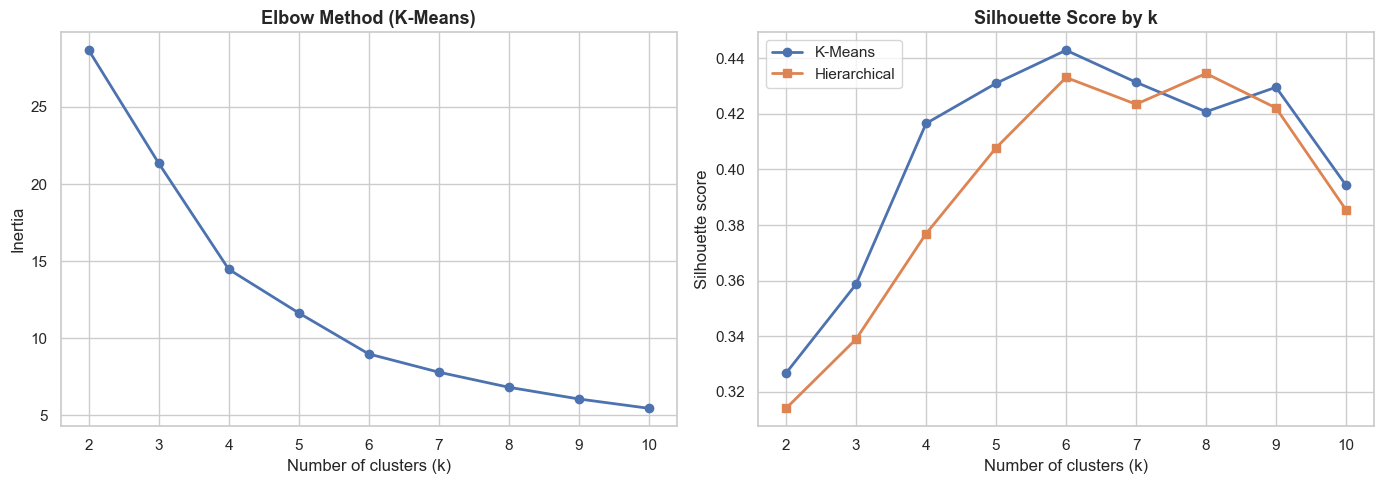

,Inertia (K-Means),Silhouette (K-Means),Silhouette (Hierarchical)
k,,,
2,28.6693,0.3267,0.3140
3,21.3443,0.3587,0.3389
4,14.4739,0.4166,0.3769
5,11.6451,0.4310,0.4078
6,8.9876,0.4429,0.4331
7,7.8076,0.4314,0.4235
8,6.8295,0.4208,0.4346
9,6.0703,0.4296,0.4222
10,5.4659,0.3943,0.3855


In [13]:
k_range = range(2, 11)
results = []
for k in k_range:
    km = Pipeline([("scaler", MinMaxScaler()),
                   ("kmeans", KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10))])
    km_labels = km.fit_predict(X)
    hc = Pipeline([("scaler", MinMaxScaler()),
                   ("hc", AgglomerativeClustering(n_clusters=k, linkage="ward"))])
    hc_labels = hc.fit_predict(X)
    results.append({"k": k,
                    "Inertia (K-Means)": km.named_steps["kmeans"].inertia_,
                    "Silhouette (K-Means)": silhouette_score(X_scaled, km_labels),
                    "Silhouette (Hierarchical)": silhouette_score(X_scaled, hc_labels)})
k_df = pd.DataFrame(results).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_df.index, k_df["Inertia (K-Means)"], "o-", linewidth=2)
axes[0].set_title("Elbow Method (K-Means)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Inertia")
axes[1].plot(k_df.index, k_df["Silhouette (K-Means)"], "o-", linewidth=2, label="K-Means")
axes[1].plot(k_df.index, k_df["Silhouette (Hierarchical)"], "s-", linewidth=2, label="Hierarchical")
axes[1].set_title("Silhouette Score by k", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Silhouette score"); axes[1].legend()
for ax in axes: ax.set_xticks(list(k_range))
plt.tight_layout()
plt.show()

k_df.style.format("{:.4f}").highlight_max(subset=["Silhouette (K-Means)", "Silhouette (Hierarchical)"], color="lightgreen")

**Elbow method**
- Inertia falls sharply from **k = 2 to k = 4** (28.67 → 14.47), then levels off. After **k = 6** (8.99), each extra cluster only removes about 1 unit of inertia.
- The elbow is therefore around **k = 5–6**.

**Silhouette score**

| | Best k | Score | Score at k = 6 |
|---|---|---|---|
| **K-Means** | **6** | **0.4429** | 0.4429 |
| **Hierarchical** | 8 | 0.4346 | 0.4331 |

- **K-Means scores higher than Hierarchical at every k except 8.**
- Hierarchical peaks at k = 8, but its score at k = 6 (0.4331) is almost the same. That makes **k = 6** a strong choice for both algorithms.

**Chosen k = 6:** it is K-Means' best silhouette score, it sits at the elbow, and six segments are still few enough for a marketing team to act on.

### 4.1 Dendrogram (Hierarchical Clustering)

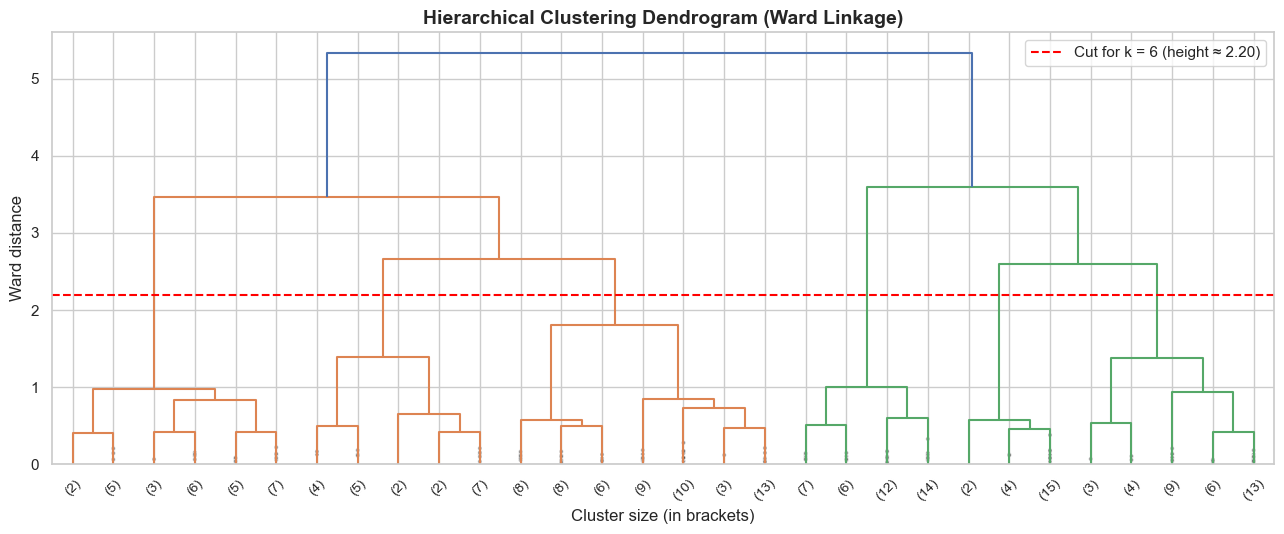

In [14]:
FINAL_K = 6
linkage_matrix = linkage(X_scaled, method="ward")
# Cut height that produces exactly FINAL_K clusters (midpoint between the two relevant merges)
cut_height = (linkage_matrix[-FINAL_K, 2] + linkage_matrix[-(FINAL_K - 1), 2]) / 2

plt.figure(figsize=(13, 5.5))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_font_size=10, show_contracted=True)
plt.axhline(y=cut_height, color="red", linestyle="--", label=f"Cut for k = {FINAL_K} (height ≈ {cut_height:.2f})")
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)", fontsize=14, fontweight="bold")
plt.xlabel("Cluster size (in brackets)"); plt.ylabel("Ward distance")
plt.legend()
plt.tight_layout()
plt.show()

- The **largest vertical gap is at the top**, where the tree splits into two main branches. This reflects the broad split between lower-spending and higher-spending customers.
- Cutting the tree at the red line gives **6 clusters**. Below that height, the merges happen at much shorter distances, which means further splits would separate customers who are already quite similar.
- The dendrogram therefore supports **k = 6** as a sensible level of detail, in line with the silhouette analysis.

## Step 5: Model Building & Evaluation (k = 6)

Both algorithms are fitted with **k = 6** and compared with three internal metrics, since there are no true labels to compare against:

| Metric | Measures | Better when |
|---|---|---|
| **Silhouette Score** | How well each customer fits its own cluster vs the nearest other cluster | Higher (max 1) |
| **Davies-Bouldin Index** | Average similarity between each cluster and its most similar cluster | Lower (min 0) |
| **Calinski-Harabasz Score** | Between-cluster spread ÷ within-cluster spread | Higher |

In [15]:
kmeans_final = Pipeline([("scaler", MinMaxScaler()),
                         ("kmeans", KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=10))])
hier_final = Pipeline([("scaler", MinMaxScaler()),
                       ("hc", AgglomerativeClustering(n_clusters=FINAL_K, linkage="ward"))])

df["KMeans_Cluster"] = kmeans_final.fit_predict(X)
df["Hier_Cluster"] = hier_final.fit_predict(X)

def metrics(labels):
    return {"Silhouette ↑": silhouette_score(X_scaled, labels),
            "Davies-Bouldin ↓": davies_bouldin_score(X_scaled, labels),
            "Calinski-Harabasz ↑": calinski_harabasz_score(X_scaled, labels)}

eval_df = pd.DataFrame({"K-Means": metrics(df["KMeans_Cluster"]),
                        "Hierarchical": metrics(df["Hier_Cluster"])}).T
eval_df.style.format("{:.4f}")

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑
K-Means,0.4429,0.8060,149.0362
Hierarchical,0.4331,0.8312,132.7278


| Metric | K-Means | Hierarchical | Better |
|---|---|---|---|
| Silhouette ↑ | **0.4429** | 0.4331 | K-Means |
| Davies-Bouldin ↓ | **0.8060** | 0.8312 | K-Means |
| Calinski-Harabasz ↑ | **149.04** | 132.73 | K-Means |

- **K-Means is better on all three metrics.** Its clusters are slightly more compact and better separated.
- A **silhouette score of about 0.44** means **moderate** structure. The segments are real, but some customers sit near the boundary between two segments, which is typical for customer data.
- A **Davies-Bouldin index below 1** for both models shows the clusters are reasonably distinct.
- The two algorithms give similar scores, which suggests the segments are **stable** rather than an artefact of one method.

**Final model: K-Means with k = 6.**

### 5.1 Visualising the Clusters with PCA

Variance explained by PC1 + PC2: 78.2% (PC1 43.0%, PC2 35.2%)


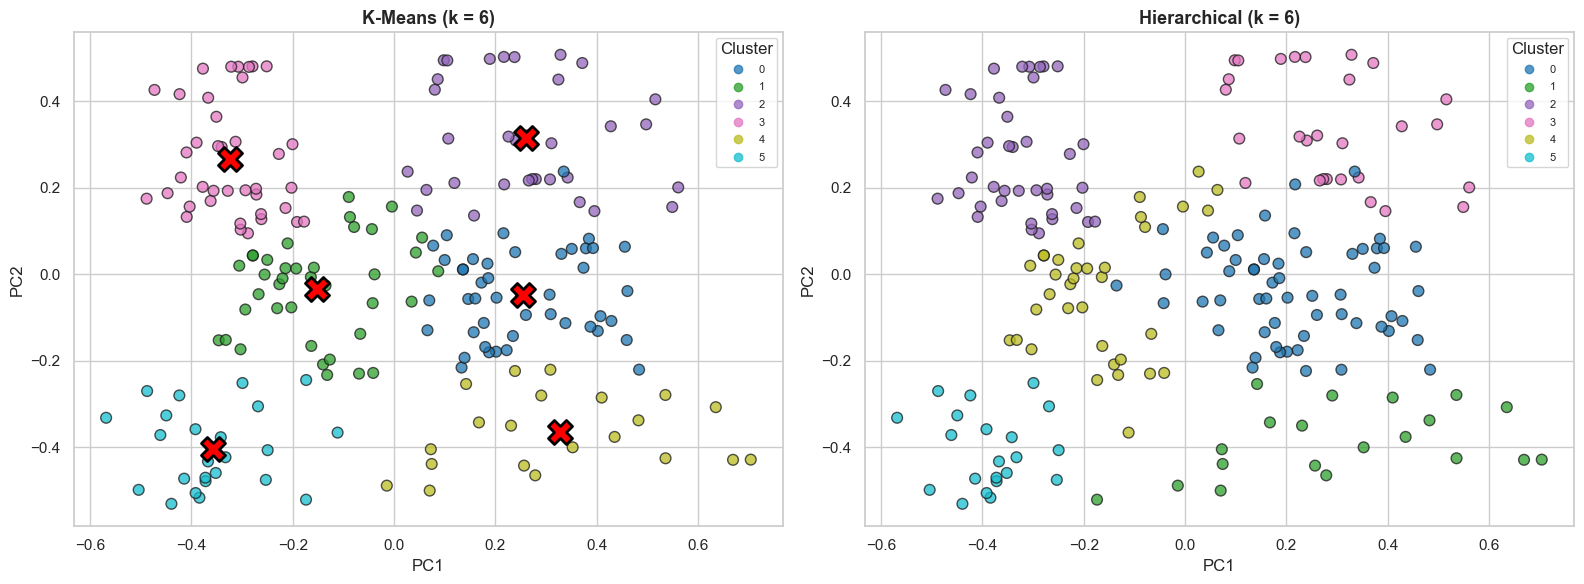

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_points = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_final.named_steps["kmeans"].cluster_centers_)
print(f"Variance explained by PC1 + PC2: {pca.explained_variance_ratio_.sum()*100:.1f}% "
      f"(PC1 {pca.explained_variance_ratio_[0]*100:.1f}%, PC2 {pca.explained_variance_ratio_[1]*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, title in zip(axes, ["KMeans_Cluster", "Hier_Cluster"], ["K-Means (k = 6)", "Hierarchical (k = 6)"]):
    sc = ax.scatter(pca_points[:, 0], pca_points[:, 1], c=df[col], cmap="tab10", s=60, alpha=0.75, edgecolors="k")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(*sc.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], c="red", marker="X", s=300, edgecolors="black", linewidths=2)
plt.tight_layout()
plt.show()

The two principal components keep about **78%** of the variance (PC1 43%, PC2 35%), so this 2D view is a fair picture of the 3D data. K-Means (centroids marked ✕) and Hierarchical produce **very similar groupings**. The main differences are at the boundaries between neighbouring clusters, which matches their close metric scores.

## Step 6: Interpreting the Clusters

Each segment is described using the customers' **original (unscaled) values**, so the numbers are in real units (years, \$k, spending score). The labels come from the final K-Means model that was evaluated above.

In [17]:
profile_df = df_raw.copy()
profile_df["Cluster"] = df["KMeans_Cluster"].values

profile = profile_df.groupby("Cluster").agg(
    Customers=("Age", "size"),
    Avg_Age=("Age", "mean"),
    Avg_Income_k=("Income (k$)", "mean"),
    Avg_Spending=("How Much They Spend", "mean"),
    Female_pct=("Gender", lambda g: (g == "Female").mean() * 100)
).round(1)
profile["Share_%"] = (profile["Customers"] / len(profile_df) * 100).round(1)
profile

,Customers,Avg_Age,Avg_Income_k,Avg_Spending,Female_pct,Share_%
Cluster,,,,,,
0,45,56.3,54.3,49.1,57.8,22.5
1,38,26.7,57.6,47.8,63.2,19.0
2,33,41.9,88.9,17.0,42.4,16.5
3,39,32.7,86.5,82.1,53.8,19.5
4,21,45.5,26.3,19.4,61.9,10.5
5,24,25.2,25.8,76.9,58.3,12.0


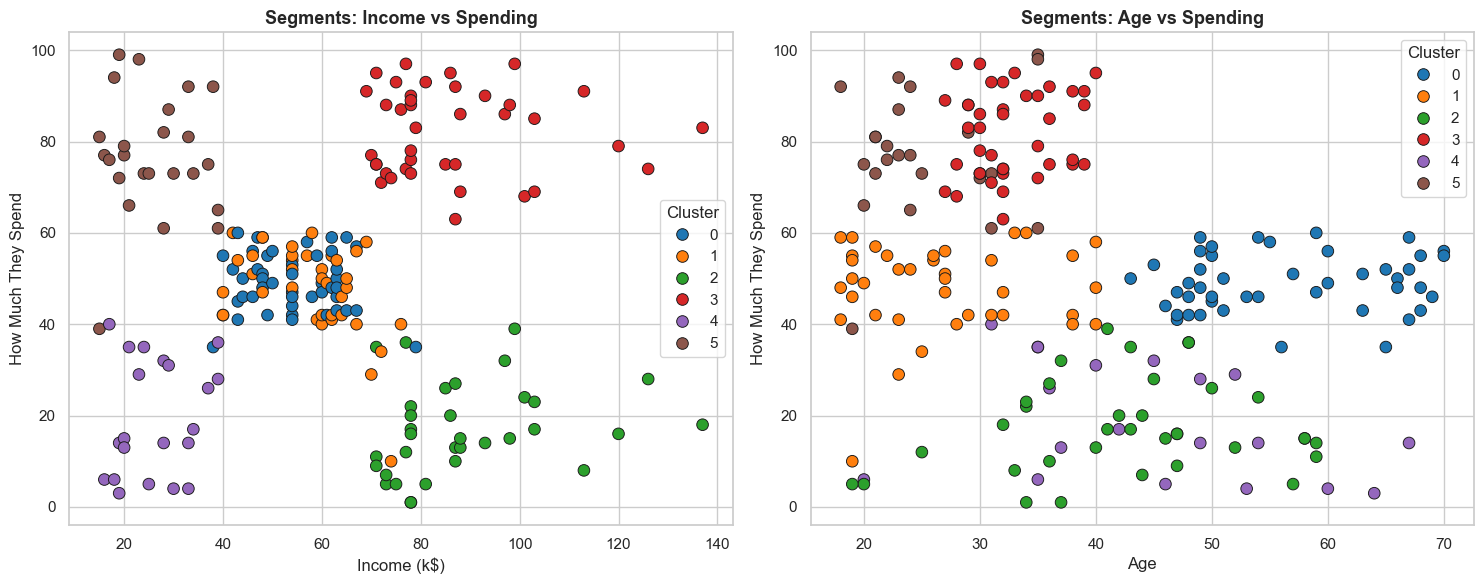

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=profile_df, x="Income (k$)", y="How Much They Spend", hue="Cluster",
                palette="tab10", s=70, ax=axes[0], edgecolor="k")
axes[0].set_title("Segments: Income vs Spending", fontsize=13, fontweight="bold")
sns.scatterplot(data=profile_df, x="Age", y="How Much They Spend", hue="Cluster",
                palette="tab10", s=70, ax=axes[1], edgecolor="k")
axes[1].set_title("Segments: Age vs Spending", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Cluster Profiles

| Cluster | Segment name | Customers (share) | Avg age | Avg income | Avg spending | Female |
|---|---|---|---|---|---|---|
| **3** | **Premium Customers** | 39 (19.5%) | 32.7 | \$86.5k | **82.1** | 54% |
| **5** | **Young Big Spenders** | 24 (12.0%) | **25.2** | \$25.8k | **76.9** | 58% |
| **2** | **Wealthy Savers** | 33 (16.5%) | 41.9 | **\$88.9k** | 17.0 | 42% |
| **0** | **Mature Moderate Spenders** | 45 (22.5%) | **56.3** | \$54.3k | 49.1 | 58% |
| **1** | **Young Moderate Spenders** | 38 (19.0%) | 26.7 | \$57.6k | 47.8 | 63% |
| **4** | **Budget Shoppers** | 21 (10.5%) | 45.5 | \$26.3k | 19.4 | 62% |

**Key observations**
- **Income does not decide spending.** The two high-income groups behave in opposite ways: Premium Customers spend 82 on average, while Wealthy Savers spend only 17. The same happens at low income: Young Big Spenders spend 77, while Budget Shoppers spend 19.
- **Age matters for the middle group.** Clusters 0 and 1 have almost the same income and spending (about \$55k, about 48), but are separated by age: about 56 vs about 27. They are the same "moderate" customers at different life stages.
- **High spenders are young.** Both high-spending segments average under 33 years old, which confirms the EDA finding that spending above 60 comes almost entirely from customers under 40.
- **Gender is fairly balanced in every segment** (42–63% female). The only group where men are the majority is **Wealthy Savers** (58% male).

### 6.1 How Well Defined Is Each Segment?

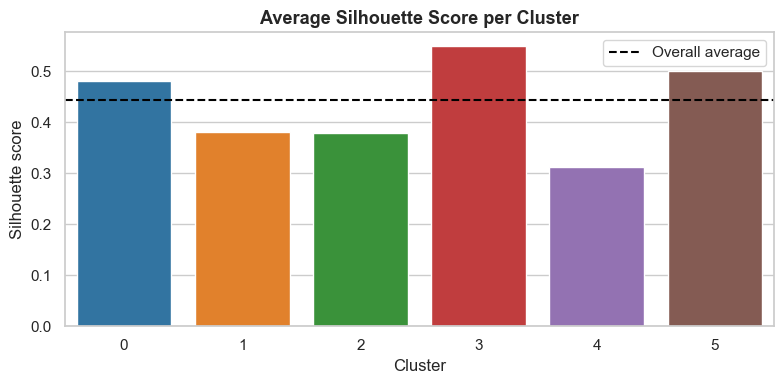

,Avg silhouette,Customers
0,0.481,45
1,0.381,38
2,0.379,33
3,0.549,39
4,0.312,21
5,0.501,24


In [19]:
sil_values = silhouette_samples(X_scaled, df["KMeans_Cluster"])
cluster_sil = (pd.Series(sil_values).groupby(df["KMeans_Cluster"].values).mean().round(3)
               .rename("Avg silhouette").to_frame())
cluster_sil["Customers"] = df["KMeans_Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
sns.barplot(x=cluster_sil.index, y=cluster_sil["Avg silhouette"], palette="tab10")
plt.axhline(silhouette_score(X_scaled, df["KMeans_Cluster"]), color="black", linestyle="--", label="Overall average")
plt.title("Average Silhouette Score per Cluster", fontsize=13, fontweight="bold")
plt.xlabel("Cluster"); plt.ylabel("Silhouette score"); plt.legend()
plt.tight_layout()
plt.show()
cluster_sil

| Cluster | Segment | Avg silhouette | vs overall (0.443) |
|---|---|---|---|
| 3 | Premium Customers | **0.549** | Well defined |
| 5 | Young Big Spenders | **0.501** | Well defined |
| 0 | Mature Moderate Spenders | **0.481** | Well defined |
| 1 | Young Moderate Spenders | 0.381 | Below average |
| 2 | Wealthy Savers | 0.379 | Below average |
| 4 | Budget Shoppers | 0.312 | Weakest |

- **Premium Customers, Young Big Spenders and Mature Moderate Spenders** are the most clearly separated groups, so marketing aimed at them can be planned with confidence.
- **Young Moderate Spenders** overlap with Mature Moderate Spenders: both have similar income and spending and differ mainly by age.
- **Budget Shoppers** (0.312) is the least distinct segment. Some of its members sit close to the Wealthy Savers and moderate groups, so it should be treated as a looser group.

## Step 7: Business Recommendations

| Priority | Segment | Share | Why | Recommended action |
|---|---|---|---|---|
| **1: Retain & reward** | **Premium Customers** (3) | 19.5% | High income and highest spending, the main revenue drivers | VIP or loyalty tier, early access to new collections, personalised service |
| **2: Grow** | **Wealthy Savers** (2) | 16.5% | Highest income but low spending: the **biggest untapped potential** | Premium-quality and value messaging, exclusive in-store events, targeted offers to understand what they are not buying |
| **3: Engage** | **Young Big Spenders** (5) | 12.0% | Spend heavily despite low income, likely trend-driven | Trend-led promotions, social media campaigns, student or "buy now, pay later" options. Avoid encouraging unaffordable debt |
| **4: Upsell** | **Young Moderate Spenders** (1) | 19.0% | Young with mid income, so spending could grow over time | Bundles, loyalty points and personalised recommendations to move them towards the premium segment |
| **5: Maintain** | **Mature Moderate Spenders** (0) | 22.5% | Largest, steady segment | Loyalty programme, comfort- and quality-focused products, reliable service |
| **6: Cost-efficient** | **Budget Shoppers** (4) | 10.5% | Low income and low spending | Discounts, value packs and seasonal sales, with low marketing spend |

**Key takeaway:** Premium Customers, Wealthy Savers and Young Big Spenders make up **48% of customers** and offer the biggest revenue opportunity. Converting even part of the **Wealthy Savers** segment into regular spenders would have the largest impact, because they already have the income.

## Final Conclusion

This project segmented 200 mall customers using **age, income and spending score**.

- **EDA** showed clear visual groups in the Income vs Spending plot, that younger customers spend more, and that gender has little effect.
- **Preprocessing:** income was capped at the 95th percentile (\$103k), the ID was dropped, and features were Min-Max scaled inside a pipeline.
- **Choosing k:** the elbow method, silhouette scores and the dendrogram all pointed to **k = 6**.
- **Model comparison:** **K-Means** beat Hierarchical clustering on all three internal metrics (silhouette **0.443** vs 0.433, Davies-Bouldin 0.806 vs 0.831, Calinski-Harabasz 149.0 vs 132.7), so it was chosen as the final model.
- **Six actionable segments:** Premium Customers, Wealthy Savers, Young Big Spenders, Young Moderate Spenders, Mature Moderate Spenders and Budget Shoppers. The clearest business finding is that **income does not determine spending**: high earners split into big spenders and savers.

### Limitations
- A silhouette score of **0.44** shows moderate separation. Some customers, especially Budget Shoppers (0.31), sit between segments and could reasonably belong to either.
- With only **200 customers** and **3 features**, the segments are broad. Purchase history, visit frequency or product categories would allow more specific targeting.
- K-Means assumes roughly spherical clusters. A density-based method such as DBSCAN could be tested to check for irregularly shaped groups.